# Сравнение пяти рекомендательных моделей на Amazon Reviews 2023 (Video Games)

Задача: персональные top-10 рекомендации видеоигр и игровых товаров пользователям Amazon.

Пять моделей из `models/` (NumPy / SciPy / PyTorch):

| # | Модель | Файл |
|---|---|---|
| 1 | Item-based коллаборативная фильтрация (соседи по товарам, asymmetric cosine + shrinkage) | `models/item_knn.py` |
| 2 | iALS — ALS для неявной обратной связи | `models/ials.py` |
| 3 | EASE | `models/ease.py` |
| 4 | Factorization Machine с метапризнаками, BPR | `models/fm.py` |
| 5 | iALS с самостоятельно разработанным таргетом «удовлетворённость × свежесть» | `models/ials_custom_target.py` |

Общие функции (метрики, top-K с исключением просмотренного, разбиение, признаки): `models/utils.py`, `models/data.py`.

### Как запустить

```bash
git clone <repo> && cd <repo>/hw1
python -m venv .venv && source .venv/bin/activate
pip install -r requirements.txt
jupyter nbconvert --to notebook --execute --inplace experiments.ipynb   # или открыть в Jupyter и Run All
```

Данные скачиваются автоматически ячейкой ниже в папку `hw1/data/` (≈ 116 МБ, в git не попадает).
Вручную: положить в `data/` два файла
* <https://mcauleylab.ucsd.edu/public_datasets/data/amazon_2023/benchmark/5core/rating_only/Video_Games.csv.gz>
* <https://mcauleylab.ucsd.edu/public_datasets/data/amazon_2023/raw/meta_categories/meta_Video_Games.jsonl.gz>

Все сиды зафиксированы (`SEED = 42`), параметры эксперимента собраны в одной ячейке `CONFIG`.
Полный прогон на CPU (8 потоков) занимает ≈ 2 часа, основное время — подбор гиперпараметров и абляции FM (≈ 1.3 ч).

In [1]:
import json
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import seaborn as sns
import torch

from models import data as D
from models import utils as U
from models.ease import EASE
from models.fm import FactorizationMachine
from models.ials import ImplicitALS
from models.ials_custom_target import CustomTargetIALS, custom_target
from models.item_knn import ItemKNN

warnings.filterwarnings("ignore", category=FutureWarning)
optuna.logging.set_verbosity(optuna.logging.WARNING)
pd.set_option("display.width", 200, "display.max_columns", 30)
sns.set_theme(style="whitegrid")

CONFIG = dict(
    SEED=42,
    DATA_DIR="data",
    N_TOP_ITEMS=10_000,        # подвыборка: самые популярные товары 5-core
    K_CORE=5,
    VAL_START="2021-01-01",    # train < VAL_START <= validation < TEST_START <= test
    TEST_START="2022-01-01",
    MIN_RATING_RELEVANT=4.0,   # релевантно = отзыв с оценкой >= 4 в периоде оценки
    K=10,
    PRIMARY_METRIC="NDCG@10",  # выбрана ДО подбора гиперпараметров
    TORCH_THREADS=8,
    N_TRIALS=dict(knn=25, ials=20, fm=8, custom=30),
)
SEED, K = CONFIG["SEED"], CONFIG["K"]
U.set_seed(SEED)
torch.set_num_threads(CONFIG["TORCH_THREADS"])
print(json.dumps(CONFIG, indent=1))

{
 "SEED": 42,
 "DATA_DIR": "data",
 "N_TOP_ITEMS": 10000,
 "K_CORE": 5,
 "VAL_START": "2021-01-01",
 "TEST_START": "2022-01-01",
 "MIN_RATING_RELEVANT": 4.0,
 "K": 10,
 "PRIMARY_METRIC": "NDCG@10",
 "TORCH_THREADS": 8,
 "N_TRIALS": {
  "knn": 25,
  "ials": 20,
  "fm": 8,
  "custom": 30
 }
}


## 1. Данные

Датасет: [Amazon Reviews 2023](https://amazon-reviews-2023.github.io/) (McAuley Lab, UC San Diego; Hou et al., Bridging Language and Items for Retrieval and Recommendation, 2024), категория Video_Games.

Используем два официальных файла:
* 5-core benchmark, rating_only — `user_id, parent_asin, rating, timestamp`: каждый пользователь и товар имеют ≥ 5 отзывов (5-core посчитан авторами датасета).
* meta_Video_Games — метаданные товаров: `title`, `main_category`, иерархия `categories` (платформа → тип товара → подтип), `store` (бренд/издатель), `price`, `details` (`Date First Available`, ESRB `Rated`, …), описания.

Взаимодействие — пользователь купил товар и оставил отзыв с оценкой 1–5 в момент `timestamp` (мс).
Явная оценка есть, но сам факт отзыва — это прежде всего неявный сигнал покупки (≈ 80 % оценок — 4–5).

Что рекомендуем: список из 10 товаров (игры, консоли, аксессуары), которые пользователь ещё не покупал/не оценивал.
Релевантный объект: товар, который пользователь в будущем (в периоде оценки) купил и оценил на ≥ 4 — то есть купил и остался доволен.

In [2]:
paths = D.download(CONFIG["DATA_DIR"])
raw = D.load_ratings(paths["ratings"])
meta_all = D.load_meta(paths["meta"])
print("ratings:", raw.shape, " meta:", meta_all.shape)
raw.head()

ratings: (814586, 4)  meta: (137269, 14)


,user_id,item_id,rating,timestamp
0,AEVPPTMG43C6GWSR7I2UGRQN7WFQ,B08R5B7YS4,1.0,1611459666223
1,AEVPPTMG43C6GWSR7I2UGRQN7WFQ,B0863MT183,4.0,1613701986538
2,AEVPPTMG43C6GWSR7I2UGRQN7WFQ,B08P8P7686,5.0,1613702112995
3,AEVPPTMG43C6GWSR7I2UGRQN7WFQ,B0B7LV3DN2,4.0,1617641445475
4,AEVPPTMG43C6GWSR7I2UGRQN7WFQ,B09WMQ6DXG,5.0,1620231368468


In [3]:
meta_all.drop(columns=["average_rating", "rating_number"]).head()

,item_id,title,main_category,platform,product_type,subtype,store,price,rated,date_first_available,n_description,n_features
0,B000FH0MHO,Dash 8-300 Professional Add-On,Video Games,PC,Games,NaN,Aerosoft,NaN,Everyone,2001-10-02,507,4
1,B00069EVOG,Phantasmagoria: A Puzzle of Flesh,Video Games,PC,Games,NaN,Sierra,NaN,Mature,2006-03-30,0,1
2,B00Z9TLVK0,NBA 2K17 - Early Tip Off Edition - PlayStation 4,Video Games,PlayStation 4,Games,NaN,2K,58.00,Everyone,2016-04-13,341,10
3,B07SZJZV88,Nintendo Selects: The Legend of Zelda Ocarina ...,Video Games,Legacy Systems,Nintendo Systems,Nintendo 3DS & 2DS,Amazon Renewed,37.42,Everyone 10+,2019-06-14,0,4
4,B002WH4ZJG,Thrustmaster Elite Fitness Pack for Nintendo Wii,Video Games,Legacy Systems,Nintendo Systems,Wii,THRUSTMASTER,NaN,NaN,2009-09-11,893,5


## 2. EDA и подготовка
### 2.1 Пропуски, дубликаты, типы

In [4]:
def basic_stats(df, name):
    n_u, n_i = df["user_id"].nunique(), df["item_id"].nunique()
    return pd.Series({"interactions": len(df), "users": n_u, "items": n_i,
                      "density, %": 100 * len(df) / (n_u * n_i),
                      "mean per user": len(df) / n_u, "mean per item": len(df) / n_i}, name=name)

print("пропуски в рейтингах:\n", raw.isna().sum().to_dict())
print("полные дубликаты строк:", raw.duplicated().sum())
print("дубликаты пары (user, item):", raw.duplicated(["user_id", "item_id"]).sum())
print("рейтинги вне 1..5:", (~raw["rating"].between(1, 5)).sum())
print("период:", pd.to_datetime(raw["timestamp"].min(), unit="ms"), "—", pd.to_datetime(raw["timestamp"].max(), unit="ms"))
print("товаров без метаданных:", (~raw["item_id"].drop_duplicates().isin(meta_all["item_id"])).sum())
basic_stats(raw, "raw 5-core").to_frame().T

пропуски в рейтингах:
 {'user_id': 0, 'item_id': 0, 'rating': 0, 'timestamp': 0}


полные дубликаты строк: 0
дубликаты пары (user, item): 0
рейтинги вне 1..5: 0
период: 1999-10-22 21:43:15 — 2023-09-02 18:14:28.630000


товаров без метаданных: 0


,interactions,users,items,"density, %",mean per user,mean per item
raw 5-core,814586.0,94762.0,25612.0,0.033563,8.596125,31.804857


Пропусков и дубликатов нет: в 5-core файле одна строка на пару (user, item), все оценки в диапазоне 1–5, метаданные есть для всех товаров.

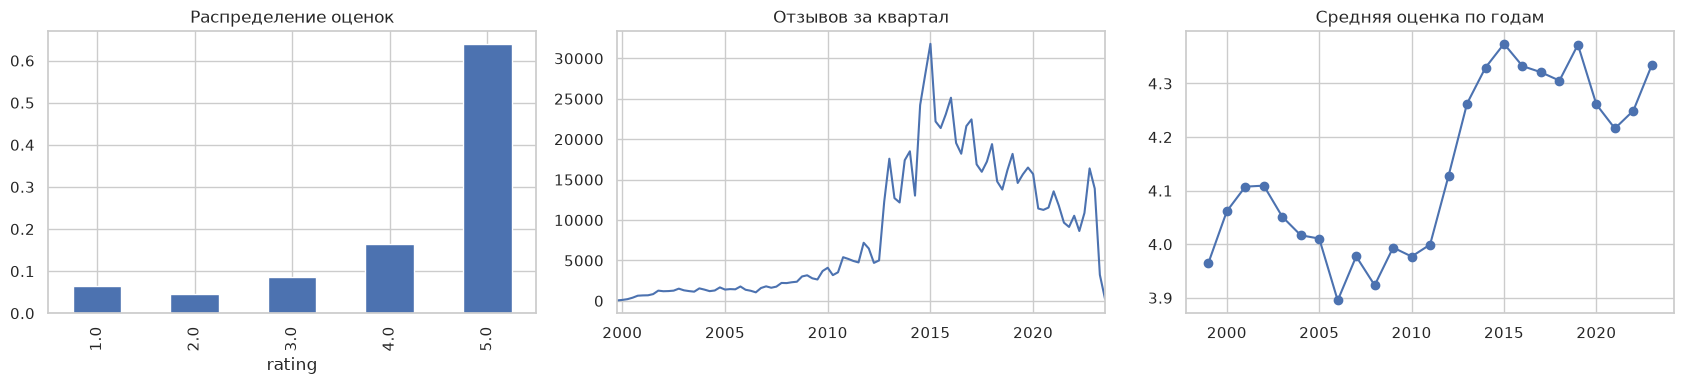

In [5]:
raw["dt"] = pd.to_datetime(raw["timestamp"], unit="ms")
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
raw["rating"].value_counts(normalize=True).sort_index().plot.bar(ax=ax[0], color="C0")
ax[0].set_title("Распределение оценок"); ax[0].set_xlabel("rating")
raw.groupby(raw["dt"].dt.to_period("Q")).size().plot(ax=ax[1])
ax[1].set_title("Отзывов за квартал"); ax[1].set_xlabel("")
raw.groupby(raw["dt"].dt.year)["rating"].mean().plot(ax=ax[2], marker="o")
ax[2].set_title("Средняя оценка по годам"); ax[2].set_xlabel("")
plt.tight_layout(); plt.show()

* Оценки сильно смещены к 5 (64 %): оценка — слабый, но полезный сигнал «доволен/нет», отзывы на 1–2 составляют ≈ 11 %.
* Активность растёт до 2015 г., затем снижается; данные заканчиваются в сентябре 2023 г. Сильная нестационарность (смена поколений консолей) — аргумент за временное разбиение и за учёт свежести взаимодействий.

### 2.2 Активность пользователей и популярность товаров

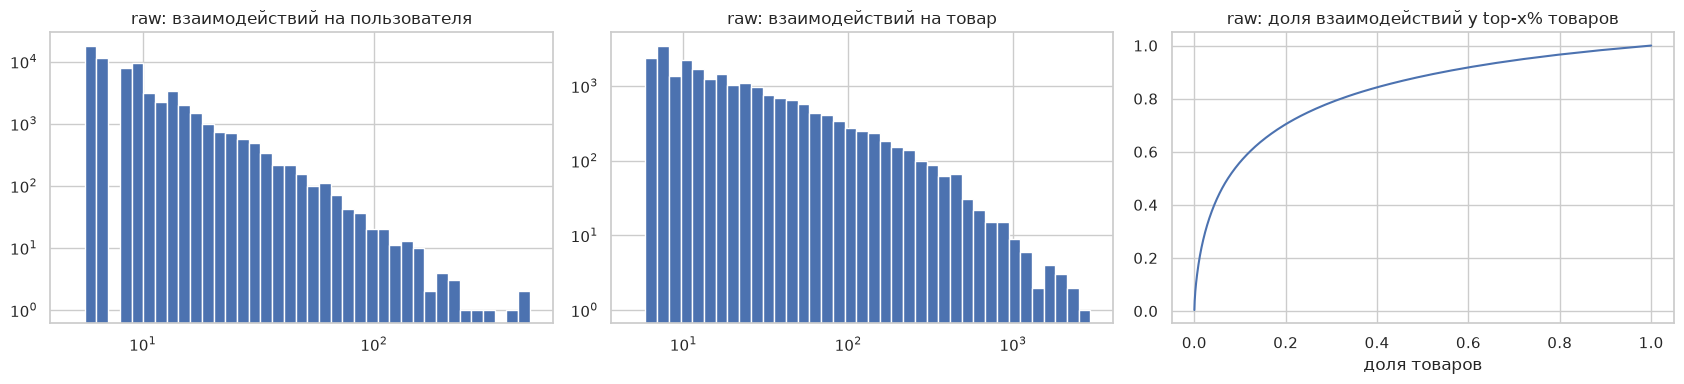

пользователи, квантили активности: {0.5: 6.0, 0.9: 14.0, 0.99: 38.0} max 473
товары, квантили популярности: {0.5: 12.0, 0.9: 64.0, 0.99: 340.8899999999994} max 2955
доля взаимодействий у top-10k товаров: 0.8381030363890369


In [6]:
def plot_activity(df, title):
    uc, ic = df.groupby("user_id").size(), df.groupby("item_id").size()
    fig, ax = plt.subplots(1, 3, figsize=(17, 4))
    ax[0].hist(uc, bins=np.logspace(np.log10(uc.min()), np.log10(uc.max()), 40)); ax[0].set_xscale("log"); ax[0].set_yscale("log")
    ax[0].set_title(f"{title}: взаимодействий на пользователя"); ax[1].set_xlabel("")
    ax[1].hist(ic, bins=np.logspace(np.log10(ic.min()), np.log10(ic.max()), 40)); ax[1].set_xscale("log"); ax[1].set_yscale("log")
    ax[1].set_title(f"{title}: взаимодействий на товар")
    s = np.sort(ic.to_numpy())[::-1]
    ax[2].plot(np.arange(1, len(s) + 1) / len(s), np.cumsum(s) / s.sum())
    ax[2].set_title(f"{title}: доля взаимодействий у top-x% товаров"); ax[2].set_xlabel("доля товаров")
    plt.tight_layout(); plt.show()
    print("пользователи, квантили активности:", uc.quantile([.5, .9, .99]).to_dict(), "max", uc.max())
    print("товары, квантили популярности:", ic.quantile([.5, .9, .99]).to_dict(), "max", ic.max())

plot_activity(raw, "raw")
ic = raw.groupby("item_id").size().sort_values(ascending=False)
print("доля взаимодействий у top-10k товаров:", ic.iloc[:CONFIG["N_TOP_ITEMS"]].sum() / len(raw))

Типичный длинный хвост: медианный пользователь написал 6 отзывов, медианный товар имеет 13 отзывов, а 10 тыс. самых популярных товаров из 25.6 тыс. покрывают ≈ 84 % взаимодействий.

### 2.3 Метаданные

,title,main_category,platform,product_type,subtype,store,price,rated,date_first_available,n_description,n_features,average_rating,rating_number
доля пропусков,0.0,0.02,0.034,0.06,0.298,0.005,0.331,0.524,0.038,0.0,0.0,0.0,0.0


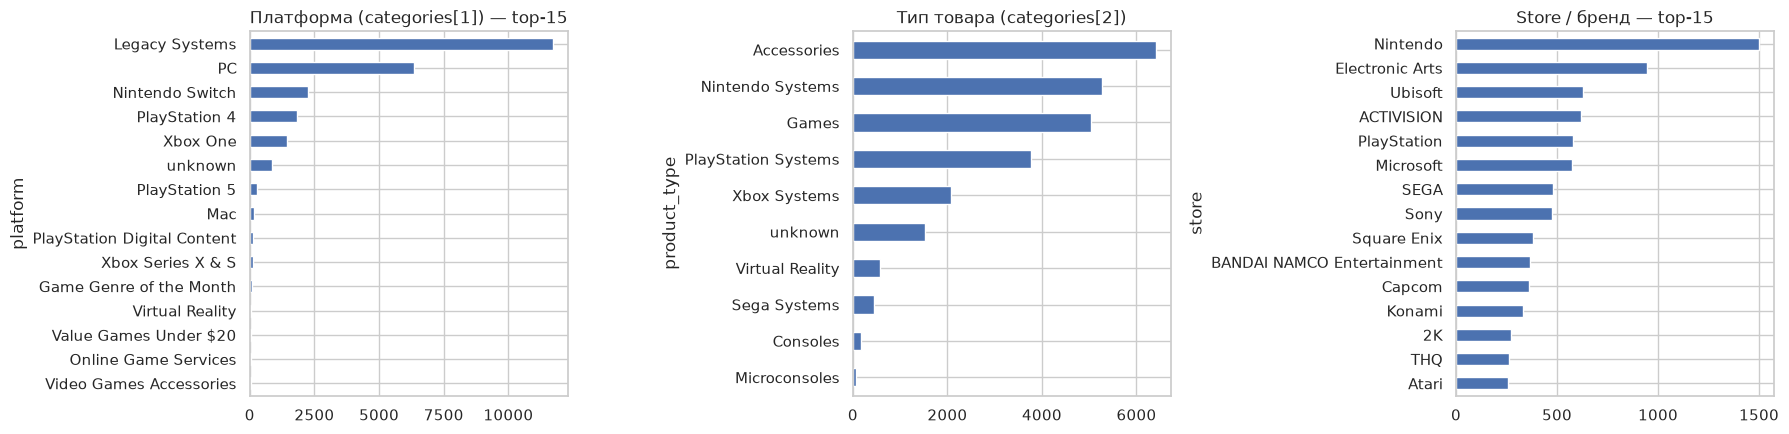

In [7]:
meta = meta_all[meta_all["item_id"].isin(set(raw["item_id"]))].copy()
miss = meta.drop(columns=["item_id"]).isna().mean().rename("доля пропусков").to_frame()
display(miss.T.round(3))

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
meta["platform"].fillna("unknown").value_counts().head(15).plot.barh(ax=ax[0]); ax[0].set_title("Платформа (categories[1]) — top-15"); ax[0].invert_yaxis()
meta["product_type"].fillna("unknown").value_counts().head(10).plot.barh(ax=ax[1]); ax[1].set_title("Тип товара (categories[2])"); ax[1].invert_yaxis()
meta["store"].fillna("unknown").value_counts().head(15).plot.barh(ax=ax[2]); ax[2].set_title("Store / бренд — top-15"); ax[2].invert_yaxis()
plt.tight_layout(); plt.show()

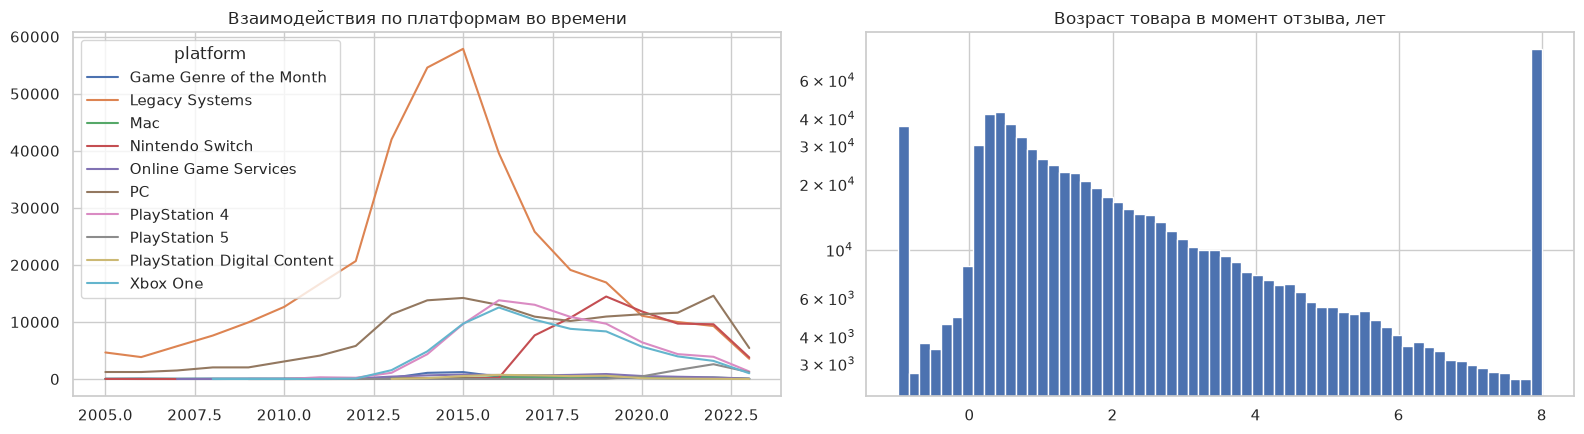

доля отзывов на товары младше 1 года: 0.29 | отзыв раньше 'Date First Available': 0.076


In [8]:
m_r = raw.merge(meta[["item_id", "platform", "product_type", "date_first_available"]], on="item_id")
fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
top_pl = m_r["platform"].value_counts().head(10).index
(m_r[m_r["platform"].isin(top_pl)].groupby([m_r["dt"].dt.year, "platform"]).size()
     .unstack().loc[2005:].plot(ax=ax[0], legend=True))
ax[0].set_title("Взаимодействия по платформам во времени"); ax[0].set_xlabel("")
age = (m_r["dt"] - m_r["date_first_available"]).dt.days
age = age[(m_r["date_first_available"].dt.year >= 1990)]
ax[1].hist(age.clip(-365, 365 * 8) / 365, bins=60); ax[1].set_title("Возраст товара в момент отзыва, лет"); ax[1].set_yscale("log")
plt.tight_layout(); plt.show()
print("доля отзывов на товары младше 1 года:", (age.between(0, 365)).mean().round(3),
      "| отзыв раньше 'Date First Available':", (age < 0).mean().round(3))

Выводы по метаданным:
* Платформа (PC, PlayStation 4, Nintendo Switch, Xbox One, Legacy …) и тип (Games / Accessories / Digital Content …) заполнены у ~90 % товаров и описывают главную ось интересов: пользователь покупает под ту консоль, которая у него есть. Популярность платформ резко меняется во времени.
* Store (бренд/издатель) почти всегда заполнен — длинный хвост, редкие значения объединяем в `other`.
* Price пропущен у ~половины товаров — кодируем квантильным бакетом + отдельный бакет `missing`. Важно: цена — снимок на 2023 г.; это статический атрибут товара и не содержит информации о будущих покупках пользователя, но может быть неточен для старых периодов (ограничение).
* Date First Available — позволяет считать возраст товара в момент рекомендации: большая доля покупок приходится на новые товары, поэтому возраст — осмысленный контекстный признак взаимодействия. Небольшая доля отзывов раньше даты появления — шум источника, возраст обрезаем снизу нулём; даты раньше 1990 г. (плейсхолдеры 1899-12-30) считаем неизвестными.
* `average_rating`, `rating_number`, Best Sellers Rank собраны в 2023 г., т.е. после периода оценки и включают будущие отзывы — это утечка, в модели не используем.

### 2.4 Очистка и подвыборка

1. Берём официальный 5-core (пропусков/дубликатов нет, очистка не требуется).
2. Подвыборка: 10 000 самых популярных товаров (по числу отзывов во всём 5-core, ничьи — по `item_id`), затем повторный итеративный 5-core (пользователи и товары с ≥ 5 взаимодействиями). Процедура детерминирована.
   Зачем: EASE требует плотной матрицы `items × items` и её обращения (25.6k² float64 ≈ 5 ГБ не помещается в память машины), item-based CF — тоже. 10k товаров покрывают 84 % взаимодействий, а отрезается хвост из товаров с ≤ 13 отзывами за 20 лет, для которых коллаборативный сигнал всё равно очень слаб.

In [9]:
df = D.subsample(raw.drop(columns="dt"), n_items=CONFIG["N_TOP_ITEMS"], k=CONFIG["K_CORE"])
df["u"] = df["user_id"].astype("category").cat.codes.astype(np.int64)
df["i"] = df["item_id"].astype("category").cat.codes.astype(np.int64)
df["ts"] = df["timestamp"]
item_index = df["item_id"].astype("category").cat.categories
N_USERS, N_ITEMS = int(df["u"].max() + 1), int(df["i"].max() + 1)
pd.concat([basic_stats(raw, "исходный 5-core"), basic_stats(df, "итоговая подвыборка")], axis=1).T.round(3)

,interactions,users,items,"density, %",mean per user,mean per item
исходный 5-core,814586.0,94762.0,25612.0,0.034,8.596,31.805
итоговая подвыборка,604335.0,71734.0,9994.0,0.084,8.425,60.470


Итог: ≈ 604 тыс. взаимодействий, ≈ 71.7 тыс. пользователей, ≈ 10 тыс. товаров, разреженность 99.92 %.

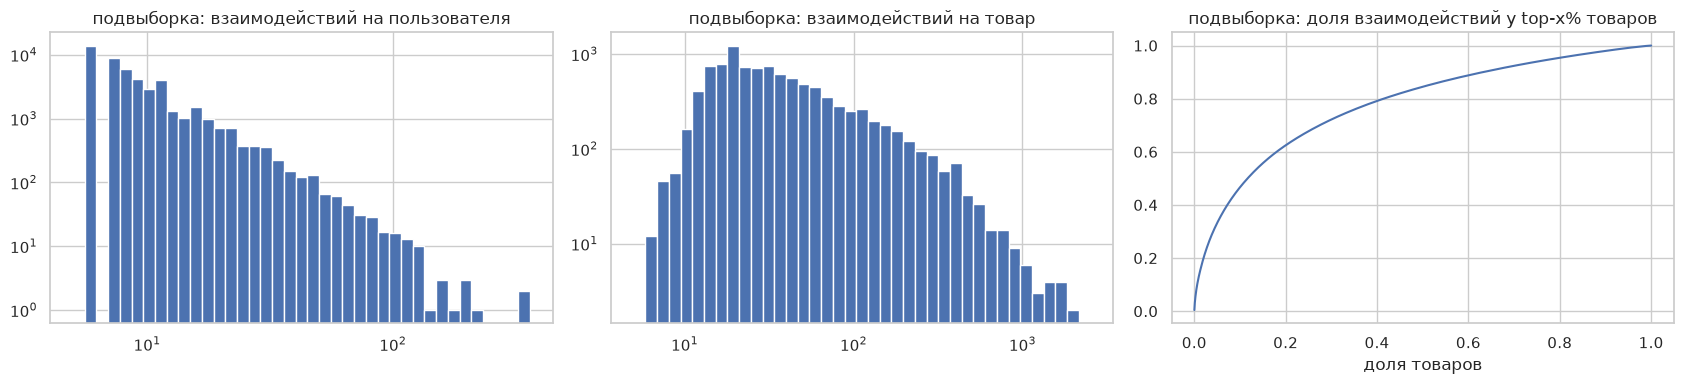

пользователи, квантили активности: {0.5: 6.0, 0.9: 13.0, 0.99: 36.0} max 361
товары, квантили популярности: {0.5: 29.0, 0.9: 129.0, 0.99: 475.0699999999997} max 2528


In [10]:
plot_activity(df.assign(dt=0), "подвыборка")

## 3. Протокол оценки

* Временное глобальное разбиение:
  * validation-фаза: обучение на всех взаимодействиях до 2021-01-01, оценка на взаимодействиях 2021 г.;
  * test-фаза: обучение на всём до 2022-01-01 (train + validation) с выбранными гиперпараметрами, оценка на 2022-01-01 … 2023-09 (≈ 20 мес.).
  Глобальная граница по времени (а не leave-last-out) моделирует реальное использование: модель, обученная в момент T, рекомендует на будущее и не видит будущих взаимодействий других пользователей.
* Релевантность: взаимодействие в периоде оценки с оценкой ≥ 4.
* Кандидаты: все товары, встречавшиеся в обучающей части (≈ 9.9k). Товары, впервые появившиеся в периоде оценки (холодные), не могут быть рекомендованы ни одной CF-моделью и исключаются из ground truth для всех одинаково (≈ 25 % тестовых взаимодействий — ограничение протокола).
* Исключение известного: из рекомендаций удаляются товары из истории пользователя в обучающей части; такие товары исключаются и из ground truth (повторные отзывы на тот же товар практически не встречаются).
* Пользователи: оцениваются те, у кого есть хотя бы одно взаимодействие в обучении и хотя бы один релевантный товар в периоде оценки. Новые пользователи (без истории) не оцениваются; в продакшене им отдавался бы popularity-fallback.
* Разбиение, рекомендации и метрики считаются функциями `D.make_split`, `U.recommend`, `U.evaluate`.

Метрики при K = 10 (основная — NDCG@10):
* NDCG@10 — учитывает позицию попадания в списке: пользователь видит верх ленты, попадание на 1-м месте ценнее, чем на 10-м. Основная метрика для подбора.
* Recall@10 (нормированный на min(|rel|, 10)) — какую долю будущих «удачных покупок» покрывает список; отражает полноту, важна для задачи «найти, что купит».
* Дополнительно: HitRate@10 (доля пользователей хотя бы с одним попаданием), MAP@10, Coverage@10 (доля каталога, попадающая в рекомендации) и Novelty@10 (средняя self-information −log₂ p(i) по популярности) — чтобы видеть, не сводится ли модель к рекомендации популярного.

In [11]:
def to_ms(s):
    return int(pd.Timestamp(s).value // 10**6)

T_VAL, T_TEST, T_END = to_ms(CONFIG["VAL_START"]), to_ms(CONFIG["TEST_START"]), int(df["ts"].max()) + 1
val = D.make_split(df, T_VAL, T_TEST, N_USERS, N_ITEMS, CONFIG["MIN_RATING_RELEVANT"])
test = D.make_split(df, T_TEST, T_END, N_USERS, N_ITEMS, CONFIG["MIN_RATING_RELEVANT"])

def split_report(s, name):
    h = s.holdout
    return pd.Series({
        "train interactions": len(s.train), "holdout interactions": len(h),
        "holdout: rating>=4": int((h["rating"] >= 4).sum()),
        "holdout: cold users share": 1 - h["u"].isin(s.train["u"].unique()).mean(),
        "holdout: cold items share": 1 - s.candidate_mask[h["i"]].mean(),
        "candidates": int(s.candidate_mask.sum()), "eval users": len(s.eval_users),
        "relevant per eval user": np.mean([len(r) for r in s.relevant]),
    }, name=name)

pd.concat([split_report(val, "validation"), split_report(test, "test")], axis=1).round(3)

,validation,test
train interactions,548717.000,575342.000
holdout interactions,26625.000,28993.000
holdout: rating>=4,20893.000,22866.000
holdout: cold users share,0.206,0.219
holdout: cold items share,0.167,0.246
candidates,9308.000,9630.000
eval users,7565.000,7112.000
relevant per eval user,1.743,1.832


Около 7.5k пользователей в validation и 7k в test — достаточно для устойчивых оценок (доверительные интервалы считаем бутстрепом ниже).

Вспомогательные вещи для оценки: популярность в train (для Novelty) и функция «обучить → рекомендовать → посчитать метрики».

In [12]:
def run_eval(model, split, k=K, per_user=False):
    recs = U.recommend(model, split.eval_users, split.train_csr, k, split.candidate_mask)
    pop = np.asarray(split.train_csr.sum(axis=0)).ravel()
    res = U.evaluate(recs, split.relevant, N_ITEMS, k, item_popularity=pop + 1)
    if per_user:
        return res, recs
    return res

class RecentPopular(U.PopularRecommender):
    """Baseline: популярность за последние `days` дней перед моментом рекомендации."""
    def __init__(self, split, days=180):
        tr = split.train[split.train["ts"] >= split.t_rec_ms - days * D.DAY_MS]
        self.pop = np.bincount(tr["i"], minlength=N_ITEMS).astype(np.float32)

baselines_val = {"Popular (all time)": run_eval(U.PopularRecommender().fit(val.train_csr), val),
                 "Popular (last 180 days)": run_eval(RecentPopular(val), val)}
pd.DataFrame(baselines_val).T.round(4)

,NDCG@10,Recall@10,HitRate@10,MAP@10,Coverage@10,Novelty@10
Popular (all time),0.0095,0.0151,0.0271,0.0062,0.0019,8.3747
Popular (last 180 days),0.0268,0.0520,0.0834,0.0156,0.0015,11.5907


## 4. Модели и подбор гиперпараметров на validation

Подбор — Optuna TPE (`seed=42`), целевая функция — NDCG@10 на validation.

In [13]:
tuning = {}

def tune(name, objective, n_trials, enqueue=None):
    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
    for params in enqueue or []:
        study.enqueue_trial(params)
    t0 = time.time()
    study.optimize(objective, n_trials=n_trials)
    tuning[name] = study
    print(f"{name}: best val NDCG@10 = {study.best_value:.5f}, params = {study.best_params}, {time.time() - t0:.0f}s")
    return study

def trials_table(study, top=8):
    t = study.trials_dataframe(attrs=("number", "value", "params", "user_attrs"))
    return t.sort_values("value", ascending=False).head(top)

### 4.1 Item-based коллаборативная фильтрация

Соседский метод: похожесть двух товаров определяется только тем, какие пользователи их покупали, а метаданные не используются. В коде и таблицах результатов модель обозначена как `ItemKNN` (класс в `models/item_knn.py`).

Почему item-based, а не user-based:

* Размер. В подвыборке ≈ 10 тыс. товаров и ≈ 71.7 тыс. пользователей. Матрица похожестей товар × товар (10k², ≈ 0.4 ГБ во float32) считается целиком и обрезается до top-k. Матрица пользователь × пользователь (71.7k², ≈ 20 ГБ) в память не помещается, соседей пришлось бы искать на лету для каждого запроса.
* Устойчивость похожестей. У медианного пользователя 6 взаимодействий, у медианного товара 29 (см. п. 2.4). Похожесть двух пользователей по 6 покупкам чаще всего опирается на 0–1 общий товар и получается шумной. Векторы товаров длиннее, и их похожести надёжнее.
* Стабильность во времени. Связи между товарами («игра → аксессуар к ней», «игра → продолжение серии») меняются медленнее, чем интересы конкретного пользователя. Матрицу $S$ можно пересчитывать редко, а новые покупки пользователя сразу влияют на рекомендацию $X_u S$ без переобучения.
* Интерпретируемость. Каждую рекомендацию можно объяснить конкретными товарами из истории («потому что вы купили …»).

Постановка. Похожесть товаров считается по столбцам бинарной матрицы взаимодействий $X$ (users × items):

$$s_{ij} = \frac{\langle x_i, x_j\rangle}{\|x_i\|^{2a}\,\|x_j\|^{2(1-a)} + h}$$

$a=0.5$ — обычный косинус; $a\neq0.5$ — асимметричный косинус (Aiolli, 2013), позволяющий штрафовать популярные товары-«соседи»; $h$ — shrinkage против похожестей, опирающихся на мало совместных покупок. Опционально строки $X$ взвешиваются $1/\log_2(2+|I(u)|)$ (сверхактивные пользователи меньше влияют на совстречаемость). Для каждого товара оставляем $k$ ближайших соседей, рекомендация:

$$\hat r_{uj} = \sum_{i\in I(u)} s_{ij}.$$

Пространство поиска: $k\in[10, 1000]$ (log), $h\in[0, 200]$, $a\in[0.1, 0.9]$, user weighting ∈ {False, True}.

In [14]:
def obj_knn(trial):
    p = dict(k=trial.suggest_int("k", 10, 1000, log=True),
             shrink=trial.suggest_float("shrink", 0.0, 200.0),
             alpha=trial.suggest_float("alpha", 0.1, 0.9),
             user_weighting=trial.suggest_categorical("user_weighting", [False, True]))
    res = run_eval(ItemKNN(**p).fit(val.train_csr), val)
    trial.set_user_attr("Recall@10", res["Recall@10"])
    return res["NDCG@10"]

study_knn = tune("ItemKNN", obj_knn, CONFIG["N_TRIALS"]["knn"],
                 enqueue=[dict(k=100, shrink=10.0, alpha=0.5, user_weighting=False)])
trials_table(study_knn)

ItemKNN: best val NDCG@10 = 0.01638, params = {'k': 874, 'shrink': 32.792313687054836, 'alpha': 0.7655411458572131, 'user_weighting': True}, 152s


,number,value,params_alpha,params_k,params_shrink,params_user_weighting,user_attrs_Recall@10
15,15,0.016376,0.765541,874,32.792314,True,0.027411
16,16,0.016365,0.733987,963,48.930203,True,0.027492
20,20,0.016157,0.761121,741,12.322448,False,0.026804
17,17,0.016011,0.765913,685,65.017339,True,0.027319
14,14,0.015670,0.899920,122,16.800362,True,0.026756
22,22,0.015640,0.808946,306,26.048604,False,0.026084
13,13,0.015535,0.870193,174,1.478620,True,0.024914
11,11,0.015416,0.842219,128,38.643909,True,0.026095


### 4.2 iALS (implicit ALS)

$$\min_{X,Y}\sum_{u,i} c_{ui}\,(p_{ui}-x_u^\top y_i)^2+\lambda\Big(\sum_u\|x_u\|^2+\sum_i\|y_i\|^2\Big).$$

При фиксированных $Y$ задача по каждому $x_u$ — гребневая регрессия:

$$x_u=(Y^\top Y+Y^\top(C_u-I)Y+\lambda I)^{-1}\,Y^\top C_u p_u,$$

где $Y^\top Y$ общий для всех, а поправка содержит только наблюдаемые товары. Шаги для $X$ и $Y$ чередуются. Систему решаем несколькими шагами метода сопряжённых градиентов с тёплым стартом (Takács et al., 2011) — векторизовано для всех пользователей сразу через одно плотное и одно разреженное умножение; точный решатель (`solver="exact"`) тоже реализован, проверка ниже показывает совпадение лосса. Рекомендация: $\hat r_{ui}=x_u^\top y_i$.

Пространство поиска: factors ∈ {32, 64, 128, 256}, $\lambda\in[10^{-2},10^{3}]$ (log), $\alpha\in[1,200]$ (log); 15 итераций, 3 шага CG.

In [15]:
# sanity-check: CG-решатель сходится к тому же решению, что и точный
_small = val.train_csr[:3000][:, :2000].tocsr()
_P, _W = _small.copy(), _small.copy(); _W.data[:] = 10.0
for solver, steps in [("exact", 0), ("cg", 3), ("cg", 10)]:
    m = ImplicitALS(32, reg=1.0, alpha=10.0, iterations=10, solver=solver, cg_steps=steps).fit(_small)
    print(f"{solver:5s} cg_steps={steps:2d}: objective = {m.loss(_P, _W):.3f}")

exact cg_steps= 0: objective = 15191.913
cg    cg_steps= 3: objective = 15192.999


cg    cg_steps=10: objective = 15191.912


In [16]:
def obj_ials(trial):
    p = dict(factors=trial.suggest_categorical("factors", [32, 64, 128, 256]),
             reg=trial.suggest_float("reg", 1e-2, 1e3, log=True),
             alpha=trial.suggest_float("alpha", 1.0, 200.0, log=True))
    res = run_eval(ImplicitALS(iterations=15, seed=SEED, **p).fit(val.train_csr), val)
    trial.set_user_attr("Recall@10", res["Recall@10"])
    return res["NDCG@10"]

study_ials = tune("iALS", obj_ials, CONFIG["N_TRIALS"]["ials"],
                  enqueue=[dict(factors=64, reg=1.0, alpha=10.0)])
trials_table(study_ials)

iALS: best val NDCG@10 = 0.01592, params = {'factors': 256, 'reg': 584.7230191358034, 'alpha': 130.41905959689933}, 765s


,number,value,params_alpha,params_factors,params_reg,user_attrs_Recall@10
15,15,0.015920,130.419060,256,584.723019,0.025817
9,9,0.015663,114.557776,128,498.304384,0.025801
17,17,0.015460,62.653585,256,1.519640,0.025435
6,6,0.015134,72.468045,256,673.224892,0.024432
11,11,0.015032,90.595579,128,611.359736,0.024638
19,19,0.014881,25.268558,256,13.563866,0.025099
3,3,0.014615,16.124278,32,0.332056,0.022751
14,14,0.014485,46.542600,128,32.058739,0.022994


### 4.3 EASE

Постановка (Steck, 2019). Линейный item-item автоэнкодер без скрытого слоя:

$$\min_B \|X-XB\|_F^2+\lambda\|B\|_F^2\quad \text{s.t. } \operatorname{diag}(B)=0.$$

Через множители Лагранжа получается замкнутое решение: $G=X^\top X+\lambda I$, $P=G^{-1}$,
$B_{ij}=-P_{ij}/P_{jj}$ ($i\ne j$), $B_{jj}=0$. Рекомендации $S=XB$. Обращение — через разложение Холецкого (`scipy.linalg.cho_factor`).

Единственный гиперпараметр — $\lambda$; перебираем по сетке (лог-шкала, 9 значений) — для одного параметра сетка надёжнее TPE.

In [17]:
ease_grid = [10, 30, 100, 300, 1000, 3000, 10000, 30000, 100000]
ease_rows = []
for reg in ease_grid:
    t0 = time.time()
    res = run_eval(EASE(reg=reg).fit(val.train_csr), val)
    ease_rows.append({"reg": reg, **res, "time, s": time.time() - t0})
ease_val = pd.DataFrame(ease_rows)
best_ease = {"reg": float(ease_val.loc[ease_val["NDCG@10"].idxmax(), "reg"])}
print("best EASE:", best_ease)
ease_val.round(5)

best EASE: {'reg': 100.0}


,reg,NDCG@10,Recall@10,HitRate@10,MAP@10,Coverage@10,Novelty@10,"time, s"
0,10,0.01511,0.02362,0.04243,0.00991,0.59496,11.21884,27.13670
1,30,0.01539,0.02492,0.04481,0.00975,0.54152,11.07761,25.09500
2,100,0.01615,0.02629,0.04627,0.01026,0.47599,10.87715,29.32934
3,300,0.01584,0.02672,0.04772,0.00970,0.43126,10.66788,25.96185
4,1000,0.01555,0.02636,0.04785,0.00946,0.40144,10.42729,26.36370
5,3000,0.01581,0.02705,0.04878,0.00959,0.37723,10.20503,26.05500
6,10000,0.01544,0.02589,0.04679,0.00953,0.36442,10.01956,28.21250
7,30000,0.01519,0.02540,0.04600,0.00939,0.36062,9.93351,27.61731
8,100000,0.01499,0.02510,0.04534,0.00925,0.35912,9.90464,25.69746


### 4.4 Factorization Machine с метапризнаками

Постановка (Rendle, 2010). Пример (пользователь, товар, контекст) — разреженный вектор $x$:

$$\hat y(x)=w_0+\sum_j w_j x_j+\sum_{j<l}\langle v_j,v_l\rangle x_j x_l
= w_0+\sum_j w_jx_j+\tfrac12\sum_f\Big[\big(\textstyle\sum_j v_{jf}x_j\big)^2-\sum_j v_{jf}^2x_j^2\Big].$$

Признаки делим на блок пользователя/контекста $U$ и блок товара $I$. Тогда
$\hat y = \mathrm{const}(x_U)+\sum_{j\in I}w_jx_j+\langle e_U,e_I\rangle+\mathrm{pair}(x_I)$, где $e_U=\sum_{j\in U}v_jx_j$, $e_I=\sum_{j\in I}v_jx_j$.
Слагаемое, зависящее только от пользователя, не меняет ранжирование и сокращается в BPR, поэтому ранжирование всего каталога — одно матричное умножение $E_U E_I^\top$ + смещение товара.

Обучение: BPR (Rendle et al., 2009) — $\mathcal L=-\sum\log\sigma(\hat y(u,i^+)-\hat y(u,i^-))+\text{reg}\cdot\|\theta_\text{batch}\|^2$, негативы равномерно из каталога (4 на позитив), Adam, PyTorch autograd. Число эпох — early stopping по NDCG@10 на validation (до 12 эпох).

Признаки:

| Блок | Признак | Зачем |
|---|---|---|
| U | user id | персональная компонента (как в MF) |
| U | профиль платформ пользователя: доли платформ среди его предыдущих покупок (при обучении — строго до текущего взаимодействия, при рекомендации — вся история до T) | у пользователя есть конкретные консоли; взаимодействие «профиль × платформа товара» переносит знание на редкие товары |
| I | item id | индивидуальная компонента товара |
| I | платформа, тип товара, main_category | категории — группируют товары, помогают хвосту |
| I | store / бренд (≥ 10 товаров, иначе `other`) | фанаты серий/издателей; аксессуары одного бренда |
| I | ценовой квантиль (+ `missing`) | ценовая категория: AAA-игры vs аксессуары vs консоли |
| I | ESRB-рейтинг | возрастная аудитория |
| I×t | возраст товара в момент взаимодействия (бакеты 0–30 дн, …, 4–8 лет, > 8 лет, unknown); при рекомендации — возраст на момент T | большинство покупок — новинки; признак зависит от времени, поэтому FM может «понижать» устаревшие товары |

Не используем: `average_rating`, `rating_number`, Best Sellers Rank (собраны в 2023 г. → утечка будущего), тексты отзывов (появляются вместе с самим взаимодействием).

Пространство поиска: factors ∈ {32, 64, 128}, lr ∈ [5·10⁻⁴, 10⁻²] (log), reg ∈ [10⁻⁶, 10⁻²] (log), batch 8192.

In [18]:
item_idx, item_w, n_item_feats, item_vocab, item_first_day = D.item_feature_table(meta_all, item_index)
item_meta = meta_all.set_index("item_id").reindex(item_index)
platform_codes, platform_names = pd.factorize(item_meta["platform"].fillna("unknown"), sort=True)
N_PLATFORMS = len(platform_names)
print(f"item feature space: {n_item_feats} (item ids {N_ITEMS} + metadata {n_item_feats - N_ITEMS}),",
      f"platforms in user profile: {N_PLATFORMS}, item age unknown: {np.isnan(item_first_day).mean():.3f}")
fields = pd.Series([v.split("=")[0] for v in item_vocab[N_ITEMS:]]).value_counts()
fields.rename("число значений").to_frame().T

item feature space: 10219 (item ids 9994 + metadata 225), platforms in user profile: 38, item age unknown: 0.033


,store,platform,ptype,maincat,rated,price
число значений,121,38,27,23,10,6


In [19]:
def fm_inputs(split):
    tr = split.train
    hist, full = D.platform_history(tr, platform_codes, N_PLATFORMS, N_USERS)
    return dict(users=tr["u"].to_numpy(), items=tr["i"].to_numpy(),
                days=tr["ts"].to_numpy() / D.DAY_MS, hist=hist), full

def make_fm(use_meta=True, **p):
    if use_meta:
        return FactorizationMachine(N_USERS, N_PLATFORMS, item_idx, item_w, n_item_feats,
                                    item_first_day, D.AGE_EDGES_DAYS, use_hist=True, seed=SEED, **p)
    # ablation: только user id и item id (обычная MF с BPR)
    return FactorizationMachine(N_USERS, N_PLATFORMS, item_idx[:, :1], item_w[:, :1], n_item_feats,
                                None, None, use_hist=False, seed=SEED, **p)

fm_val_inputs, fm_val_full = fm_inputs(val)

def fit_fm(split, inputs, full, use_meta=True, early_stopping=True, **p):
    model = make_fm(use_meta, **p)
    def cb(m, epoch):
        m.set_inference_context(full, split.t_rec_ms / D.DAY_MS)
        return run_eval(m, split)["NDCG@10"]
    model.fit(**inputs, n_items=N_ITEMS, callback=cb if early_stopping else None)
    model.set_inference_context(full, split.t_rec_ms / D.DAY_MS)
    return model

FM_MAX_EPOCHS = 12

def obj_fm(trial):
    p = dict(factors=trial.suggest_categorical("factors", [32, 64, 128]),
             lr=trial.suggest_float("lr", 5e-4, 1e-2, log=True),
             reg=trial.suggest_float("reg", 1e-6, 1e-2, log=True))
    m = fit_fm(val, fm_val_inputs, fm_val_full, epochs=FM_MAX_EPOCHS, batch_size=8192, **p)
    trial.set_user_attr("best_epoch", m.best_epoch_)
    trial.set_user_attr("val_curve", [round(v, 5) for v in m.val_history_])
    return max(m.val_history_)

study_fm = tune("FM", obj_fm, CONFIG["N_TRIALS"]["fm"],
                enqueue=[dict(factors=64, lr=3e-3, reg=1e-5)])
best_fm = {**study_fm.best_params, "epochs": study_fm.best_trial.user_attrs["best_epoch"], "batch_size": 8192}
print("best FM:", best_fm)
trials_table(study_fm)

FM: best val NDCG@10 = 0.02598, params = {'factors': 128, 'lr': 0.0030271829277346246, 'reg': 0.0006796578090758161}, 3120s
best FM: {'factors': 128, 'lr': 0.0030271829277346246, 'reg': 0.0006796578090758161, 'epochs': 10, 'batch_size': 8192}


,number,value,params_factors,params_lr,params_reg,user_attrs_best_epoch,user_attrs_val_curve
2,2,0.025979,128,0.003027,0.000680,10,"[0.00953, 0.0097, 0.01061, 0.01208, 0.01432, 0..."
1,1,0.021213,64,0.003005,0.000004,12,"[0.00967, 0.01025, 0.01051, 0.01133, 0.01139, ..."
0,0,0.021129,64,0.003000,0.000010,12,"[0.00968, 0.01025, 0.0105, 0.01133, 0.0114, 0...."
4,4,0.020321,128,0.001824,0.000015,12,"[0.00851, 0.00961, 0.01002, 0.01048, 0.01058, ..."
7,7,0.018032,32,0.008580,0.007287,10,"[0.00916, 0.00957, 0.01, 0.0112, 0.01329, 0.01..."
6,6,0.014577,32,0.002949,0.000002,12,"[0.0086, 0.01011, 0.01049, 0.01051, 0.01036, 0..."
5,5,0.010824,32,0.001498,0.000067,11,"[0.00808, 0.00828, 0.00936, 0.01, 0.01021, 0.0..."
3,3,0.010713,64,0.000945,0.000005,12,"[0.008, 0.00818, 0.00974, 0.01045, 0.01056, 0...."


### 4.5 iALS с кастомным таргетом «удовлетворённость × свежесть»

Мотивация. Базовый iALS регрессирует каждое наблюдённое взаимодействие на $p_{ui}=1$. На Amazon факт отзыва смешивает:
* доволен (оценка 4–5) и купил, но разочаровался (1–2) — а релевантность на test определена как «купит и оценит ≥ 4»;
* свежую покупку и покупку десятилетней давности для консоли, которой у пользователя, скорее всего, уже нет. EDA показал сильный дрейф платформ во времени.

Таргет (на наблюдённых парах; ненаблюдённые остаются $y=0$, $c=1$):

$$y_{ui}=s(r_{ui})\cdot d(t_{ui}),\qquad s(r)=\beta+(1-\beta)\frac{r-1}{4},\qquad d(t)=\delta+(1-\delta)\,2^{-(T-t)/h}$$

* $s(r)\in[\beta,1]$ — нормированная удовлетворённость: $s(5)=1$, $s(1)=\beta$. Даже низкая оценка — сигнал интереса (товар купили), поэтому $\beta>0$.
* $d(t)\in[\delta,1]$ — экспоненциальное затухание с периодом полураспада $h$ дней, $T$ — момент рекомендации (конец train), $\delta$ — «пол», чтобы старая история не обнулялась полностью.
* $\beta=\delta=1$ даёт ровно базовый iALS, поэтому сравнение изолирует эффект таргета.

Меняется целевой сигнал $y_{ui}$ (то, что модель восстанавливает скалярным произведением); confidence та же, что в базовой модели, $c_{ui}=1+\alpha$ на всех наблюдённых парах. Оптимизация та же — чередующиеся гребневые решения
$x_u=(Y^\top Y+Y^\top(C_u-I)Y+\lambda I)^{-1}Y^\top C_u y_u$; при нефиксированной (небинарной) $y_u$ меняется правая часть.
Таргет строится по рейтингам и времени обучающих взаимодействий.

Пространство поиска — то же, что у базового iALS (factors, λ, α), плюс параметры таргета: $\beta\in[0.05,1]$, $\delta\in[0,1]$, $h\in[30, 3650]$ дней (log). Первый trial — лучшая конфигурация базового iALS с $\beta=\delta=1$ (т.е. сам baseline), так что поиск стартует с него.

In [20]:
def fit_custom(split, **p):
    tr = split.train
    return CustomTargetIALS(iterations=15, seed=SEED, **p).fit_interactions(
        tr["u"].to_numpy(), tr["i"].to_numpy(), tr["rating"].to_numpy(), tr["ts"].to_numpy(),
        N_USERS, N_ITEMS, split.t_rec_ms)

def obj_custom(trial):
    p = dict(factors=trial.suggest_categorical("factors", [32, 64, 128, 256]),
             reg=trial.suggest_float("reg", 1e-2, 1e3, log=True),
             alpha=trial.suggest_float("alpha", 1.0, 200.0, log=True),
             beta=trial.suggest_float("beta", 0.05, 1.0),
             delta=trial.suggest_float("delta", 0.0, 1.0),
             half_life_days=trial.suggest_float("half_life_days", 30.0, 3650.0, log=True))
    res = run_eval(fit_custom(val, **p), val)
    trial.set_user_attr("Recall@10", res["Recall@10"])
    return res["NDCG@10"]

study_custom = tune("iALS custom target", obj_custom, CONFIG["N_TRIALS"]["custom"],
                    enqueue=[{**study_ials.best_params, "beta": 1.0, "delta": 1.0, "half_life_days": 365.0}])
trials_table(study_custom)

iALS custom target: best val NDCG@10 = 0.02478, params = {'factors': 64, 'reg': 1.5441546512901931, 'alpha': 14.968405829738193, 'beta': 0.3953792026304145, 'delta': 0.05701466862746621, 'half_life_days': 207.66330530587572}, 734s


,number,value,params_alpha,params_beta,params_delta,params_factors,params_half_life_days,params_reg,user_attrs_Recall@10
23,23,0.024777,14.968406,0.395379,0.057015,64,207.663305,1.544155,0.041337
20,20,0.024329,4.622520,0.544588,0.023832,64,367.943214,0.077078,0.039417
26,26,0.024112,12.307049,0.192720,0.072074,64,272.048570,0.617005,0.039272
22,22,0.024067,10.816405,0.646771,0.045644,64,150.553217,2.135928,0.039598
19,19,0.023446,11.170424,0.332160,0.190205,64,197.201528,3.101572,0.038893
15,15,0.023065,2.611095,0.336939,0.020843,64,253.891233,1.373719,0.039432
25,25,0.022791,22.865361,0.553205,0.074809,64,112.455162,0.061378,0.038132
27,27,0.022694,26.823762,0.178264,0.157096,64,166.592688,0.925587,0.037353


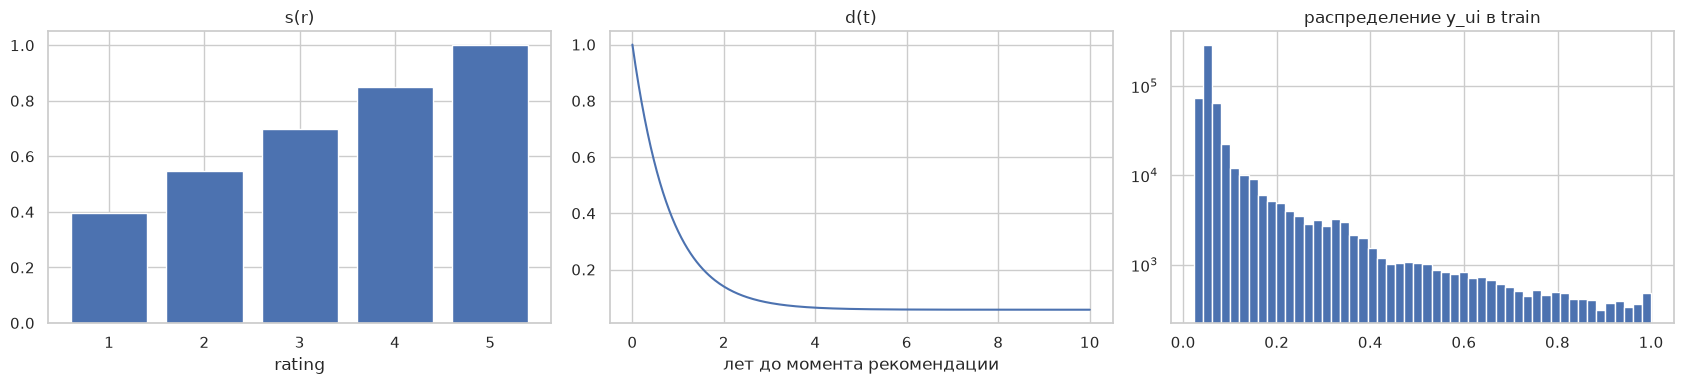

In [21]:
# как выглядит выбранный таргет на train validation-фазы
bp = study_custom.best_params
y_val = custom_target(val.train["rating"].to_numpy(), val.train["ts"].to_numpy(), val.t_rec_ms,
                      bp["beta"], bp["delta"], bp["half_life_days"])
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
r = np.arange(1, 6); ax[0].bar(r, bp["beta"] + (1 - bp["beta"]) * (r - 1) / 4); ax[0].set_title("s(r)"); ax[0].set_xlabel("rating")
days = np.linspace(0, 365 * 10, 300)
ax[1].plot(days / 365, bp["delta"] + (1 - bp["delta"]) * 2 ** (-days / bp["half_life_days"])); ax[1].set_title("d(t)"); ax[1].set_xlabel("лет до момента рекомендации")
ax[2].hist(y_val, bins=50); ax[2].set_title("распределение y_ui в train"); ax[2].set_yscale("log")
plt.tight_layout(); plt.show()

### 4.6 Влияние гиперпараметров (validation)

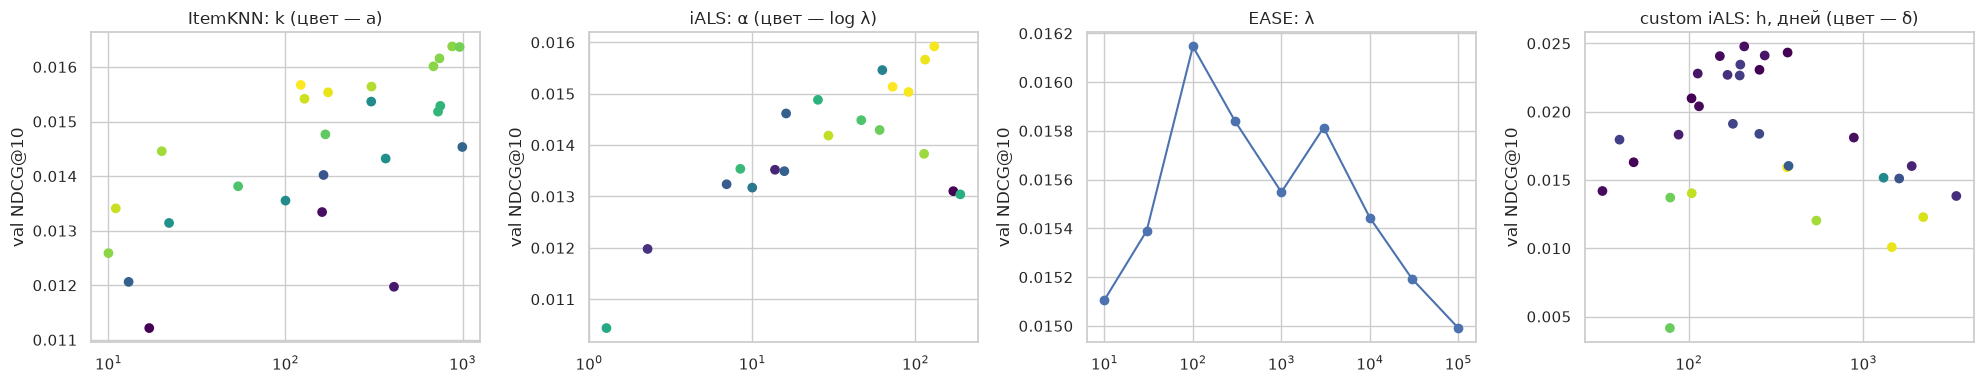

In [22]:
fig, ax = plt.subplots(1, 4, figsize=(20, 4))
t = study_knn.trials_dataframe(); ax[0].scatter(t["params_k"], t["value"], c=t["params_alpha"], cmap="viridis"); ax[0].set_xscale("log"); ax[0].set_title("ItemKNN: k (цвет — a)")
t = study_ials.trials_dataframe(); ax[1].scatter(t["params_alpha"], t["value"], c=np.log10(t["params_reg"]), cmap="viridis"); ax[1].set_xscale("log"); ax[1].set_title("iALS: α (цвет — log λ)")
ax[2].plot(ease_val["reg"], ease_val["NDCG@10"], marker="o"); ax[2].set_xscale("log"); ax[2].set_title("EASE: λ")
t = study_custom.trials_dataframe(); sc = ax[3].scatter(t["params_half_life_days"], t["value"], c=t["params_delta"], cmap="viridis"); ax[3].set_xscale("log"); ax[3].set_title("custom iALS: h, дней (цвет — δ)")
for a in ax: a.set_ylabel("val NDCG@10")
plt.tight_layout(); plt.show()

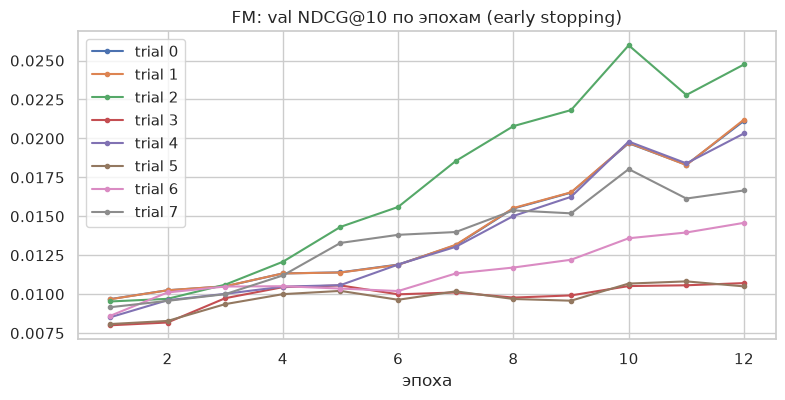

In [23]:
fm_curves = pd.DataFrame({f"trial {tr.number}": tr.user_attrs["val_curve"] for tr in study_fm.trials})
fm_curves.index = np.arange(1, len(fm_curves) + 1)
fm_curves.plot(figsize=(9, 4), marker=".", title="FM: val NDCG@10 по эпохам (early stopping)"); plt.xlabel("эпоха"); plt.show()

## 5. Финальное сравнение на test

Все модели переобучаются на train + validation (всё до 2022-01-01) с выбранными гиперпараметрами и оцениваются один раз на test. Для FM число эпох фиксировано лучшей эпохой с validation.

In [24]:
best = {
    "ItemKNN": study_knn.best_params,
    "iALS": {**study_ials.best_params, "iterations": 15},
    "EASE": best_ease,
    "FM (metadata)": best_fm,
    "iALS custom target": {**study_custom.best_params, "iterations": 15},
}
fm_test_inputs, fm_test_full = fm_inputs(test)

def build(name, split, inputs=None, full=None):
    p = best[name]
    if name == "ItemKNN":
        return ItemKNN(**p).fit(split.train_csr)
    if name == "iALS":
        return ImplicitALS(seed=SEED, **p).fit(split.train_csr)
    if name == "EASE":
        return EASE(**p).fit(split.train_csr)
    if name == "FM (metadata)":
        return fit_fm(split, inputs, full, early_stopping=False, **p)
    if name == "iALS custom target":
        q = {k: v for k, v in p.items() if k != "iterations"}
        return fit_custom(split, **q)

results, per_user_ndcg, test_recs, fit_time = {}, {}, {}, {}
for name, model in [("Popular (all time)", U.PopularRecommender().fit(test.train_csr)),
                    ("Popular (last 180 days)", RecentPopular(test))]:
    results[name], test_recs[name] = run_eval(model, test, per_user=True)
for name in best:
    t0 = time.time()
    model = build(name, test, fm_test_inputs, fm_test_full)
    fit_time[name] = time.time() - t0
    results[name], test_recs[name] = run_eval(model, test, per_user=True)
    print(f"{name:22s} fit {fit_time[name]:6.1f}s  NDCG@10 {results[name]['NDCG@10']:.5f}")
for name, recs in test_recs.items():
    per_user_ndcg[name] = U.ndcg_at_k(recs, test.relevant, K)

ItemKNN                fit    5.4s  NDCG@10 0.01323


iALS                   fit   84.9s  NDCG@10 0.01515


EASE                   fit   28.9s  NDCG@10 0.01395


FM (metadata)          fit  657.5s  NDCG@10 0.02492


iALS custom target     fit   20.4s  NDCG@10 0.02466


In [25]:
val_ndcg = {"ItemKNN": study_knn.best_value, "iALS": study_ials.best_value,
            "EASE": float(ease_val["NDCG@10"].max()), "FM (metadata)": study_fm.best_value,
            "iALS custom target": study_custom.best_value,
            **{k: v["NDCG@10"] for k, v in baselines_val.items()}}
table = pd.DataFrame(results).T
table.insert(0, "val NDCG@10", pd.Series(val_ndcg))
table["fit time, s"] = pd.Series(fit_time)
table["hyperparameters"] = pd.Series({k: json.dumps({kk: (round(vv, 4) if isinstance(vv, float) else vv) for kk, vv in v.items()}) for k, v in best.items()})
table = table.sort_values("NDCG@10", ascending=False)
table.style.format({c: "{:.4f}" for c in table.columns if "@" in c} | {"fit time, s": "{:.1f}"}).background_gradient(subset=["NDCG@10", "Recall@10"], cmap="Greens")

,val NDCG@10,NDCG@10,Recall@10,HitRate@10,MAP@10,Coverage@10,Novelty@10,"fit time, s",hyperparameters
FM (metadata),0.0260,0.0249,0.0449,0.0744,0.0151,0.0853,11.7849,657.5,"{""factors"": 128, ""lr"": 0.003, ""reg"": 0.0007, ""epochs"": 10, ""batch_size"": 8192}"
iALS custom target,0.0248,0.0247,0.0381,0.0643,0.0166,0.1462,11.9791,20.4,"{""factors"": 64, ""reg"": 1.5442, ""alpha"": 14.9684, ""beta"": 0.3954, ""delta"": 0.057, ""half_life_days"": 207.6633, ""iterations"": 15}"
Popular (last 180 days),0.0268,0.0237,0.0499,0.0844,0.0121,0.0016,12.3278,nan,nan
iALS,0.0159,0.0152,0.0239,0.0440,0.0095,0.2402,10.8713,84.9,"{""factors"": 256, ""reg"": 584.723, ""alpha"": 130.4191, ""iterations"": 15}"
EASE,0.0161,0.0140,0.0228,0.0418,0.0085,0.4691,10.9518,28.9,"{""reg"": 100.0}"
ItemKNN,0.0164,0.0132,0.0211,0.0395,0.0081,0.3747,10.3470,5.4,"{""k"": 874, ""shrink"": 32.7923, ""alpha"": 0.7655, ""user_weighting"": true}"
Popular (all time),0.0095,0.0070,0.0120,0.0221,0.0044,0.0018,8.4120,nan,nan


Значимость. Парный бутстреп по пользователям (одни и те же пользователи для обеих моделей, 1000 ресэмплов): 95 % ДИ разности NDCG@10 относительно лучшей модели.

In [26]:
best_name = table.index[0]
rows = []
for name in table.index[1:]:
    mean, lo, hi = U.paired_bootstrap(per_user_ndcg[best_name], per_user_ndcg[name], seed=SEED)
    rows.append({"vs": name, "ΔNDCG@10": mean, "CI low": lo, "CI high": hi, "significant": lo > 0 or hi < 0})
print("лучшая модель:", best_name)
pd.DataFrame(rows).round(5)

лучшая модель: FM (metadata)


,vs,ΔNDCG@10,CI low,CI high,significant
0,iALS custom target,0.00026,-0.00287,0.00362,False
1,Popular (last 180 days),0.00125,-0.00157,0.00386,False
2,iALS,0.00977,0.00682,0.01266,True
3,EASE,0.01097,0.00813,0.01374,True
4,ItemKNN,0.01169,0.00887,0.01455,True
5,Popular (all time),0.01787,0.01503,0.02034,True


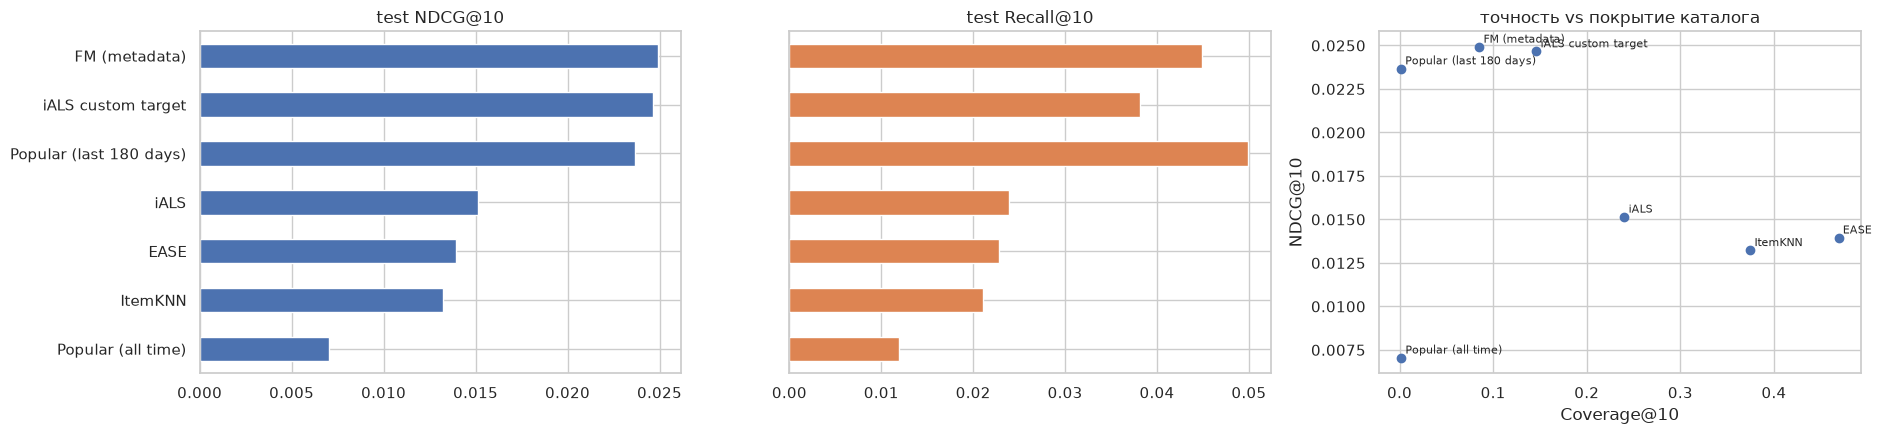

In [27]:
fig, ax = plt.subplots(1, 3, figsize=(19, 4.5))
order = table.index[::-1]
table.loc[order, "NDCG@10"].plot.barh(ax=ax[0], color="C0"); ax[0].set_title("test NDCG@10")
table.loc[order, "Recall@10"].plot.barh(ax=ax[1], color="C1"); ax[1].set_title("test Recall@10"); ax[1].set_yticklabels([])
ax[2].scatter(table["Coverage@10"], table["NDCG@10"])
for n, r in table.iterrows():
    ax[2].annotate(n, (r["Coverage@10"], r["NDCG@10"]), fontsize=8, xytext=(3, 3), textcoords="offset points")
ax[2].set_xlabel("Coverage@10"); ax[2].set_ylabel("NDCG@10"); ax[2].set_title("точность vs покрытие каталога")
plt.tight_layout(); plt.show()

### 5.1 Качество по сегментам активности пользователей (test)

In [28]:
hist_len = np.asarray(test.train_csr.sum(axis=1)).ravel()[test.eval_users]
bins = pd.cut(hist_len, [0, 5, 10, 20, 50, np.inf], labels=["1–5", "6–10", "11–20", "21–50", ">50"])
seg = pd.DataFrame({n: per_user_ndcg[n] for n in table.index}).groupby(bins, observed=True).mean()
seg.insert(0, "users", pd.Series(bins).value_counts().reindex(seg.index).to_numpy())
seg.round(4)

,users,FM (metadata),iALS custom target,Popular (last 180 days),iALS,EASE,ItemKNN,Popular (all time)
1–5,4130,0.0237,0.0248,0.0223,0.0167,0.0153,0.0149,0.0071
6–10,1901,0.0255,0.0209,0.0230,0.0123,0.0119,0.0104,0.0077
11–20,764,0.0296,0.0301,0.0275,0.0152,0.0120,0.0119,0.0065
21–50,273,0.0233,0.0304,0.0344,0.0130,0.0130,0.0122,0.0028
>50,44,0.0451,0.0374,0.0452,0.0066,0.0172,0.0112,0.0067


### 5.2 Абляции (анализ после выбора моделей)

Чтобы понять, откуда берётся качество, с теми же выбранными гиперпараметрами обучаем:
* FM без метаданных — только user id + item id (BPR-MF), те же factors/lr/reg/эпохи;
* кастомный таргет по компонентам — только рейтинг ($\delta=1$), только свежесть ($\beta=1$), оба, и базовый ($\beta=\delta=1$) при одинаковых factors/λ/α.

Абляции считаем и на validation, и на test.

In [29]:
abl = {}
for split_name, split, (inputs, full) in [("val", val, (fm_val_inputs, fm_val_full)), ("test", test, (fm_test_inputs, fm_test_full))]:
    for use_meta in [True, False]:
        m = fit_fm(split, inputs, full, use_meta=use_meta, early_stopping=False, **best_fm)
        abl[(f"FM: {'ids + metadata' if use_meta else 'ids only'}", split_name)] = run_eval(m, split)
    cp = {k: v for k, v in study_custom.best_params.items()}
    variants = {"iALS target: baseline (β=δ=1)": dict(beta=1.0, delta=1.0),
                "iALS target: rating only (δ=1)": dict(beta=cp["beta"], delta=1.0),
                "iALS target: recency only (β=1)": dict(beta=1.0, delta=cp["delta"]),
                "iALS target: rating × recency": dict(beta=cp["beta"], delta=cp["delta"])}
    for vname, v in variants.items():
        q = {**cp, **v}
        abl[(vname, split_name)] = run_eval(fit_custom(split, **q), split)
abl_df = pd.DataFrame(abl).T[["NDCG@10", "Recall@10", "HitRate@10", "Coverage@10"]].unstack(1)
abl_df.round(4)

NDCG@10         Recall@10         HitRate@10         Coverage@10        
                                   test     val      test     val       test     val        test     val
FM: ids + metadata               0.0249  0.0260    0.0449  0.0479     0.0744  0.0742      0.0853  0.0958
FM: ids only                     0.0122  0.0128    0.0190  0.0212     0.0374  0.0399      0.3662  0.3557
iALS target: baseline (β=δ=1)    0.0127  0.0134    0.0201  0.0221     0.0377  0.0402      0.1446  0.1428
iALS target: rating only (δ=1)   0.0119  0.0135    0.0190  0.0220     0.0366  0.0399      0.1418  0.1427
iALS target: rating × recency    0.0247  0.0248    0.0381  0.0413     0.0643  0.0661      0.1462  0.1416
iALS target: recency only (β=1)  0.0245  0.0250    0.0396  0.0410     0.0681  0.0672      0.1413  0.1341

Кастомный таргет против базового iALS из п. 4.2, каждый со своими лучшими на validation гиперпараметрами:

In [30]:
mean, lo, hi = U.paired_bootstrap(per_user_ndcg["iALS custom target"], per_user_ndcg["iALS"], seed=SEED)
print(f"test NDCG@10: custom {results['iALS custom target']['NDCG@10']:.5f} vs baseline iALS {results['iALS']['NDCG@10']:.5f}; "
      f"Δ = {mean:.5f}, 95% CI [{lo:.5f}, {hi:.5f}]")
print(f"test Recall@10: custom {results['iALS custom target']['Recall@10']:.5f} vs baseline iALS {results['iALS']['Recall@10']:.5f}")

test NDCG@10: custom 0.02466 vs baseline iALS 0.01515; Δ = 0.00950, 95% CI [0.00640, 0.01235]
test Recall@10: custom 0.03810 vs baseline iALS 0.02389


### 5.3 Пример рекомендаций

In [31]:
titles = item_meta["title"].fillna("?").str.slice(0, 60).to_numpy()
plats = item_meta["platform"].fillna("?").to_numpy()
rng = np.random.default_rng(SEED)
pos = int(rng.choice(np.flatnonzero(hist_len >= 8)))
u = test.eval_users[pos]
h = test.train[test.train["u"] == u].sort_values("ts").tail(8)
print("последние покупки пользователя (до 2022):")
for _, r in h.iterrows():
    print(f"  {pd.to_datetime(r.ts, unit='ms').date()}  {r.rating:.0f}★  [{plats[r.i]}] {titles[r.i]}")
print("релевантные в test:", [f"[{plats[i]}] {titles[i]}" for i in test.relevant[pos]])
for name in [best_name, "iALS", "FM (metadata)"]:
    print(f"\n{name}:")
    for i in test_recs[name][pos]:
        print(f"  {'✔' if i in test.relevant[pos] else ' '} [{plats[i]}] {titles[i]}")

последние покупки пользователя (до 2022):
  2018-08-20  4★  [Nintendo Switch] Nintendo Switch Dock Set
  2018-09-15  5★  [PC] Razer BlackWidow X Chroma Mechanical Gaming Keyboard: Green 
  2019-01-18  1★  [Nintendo Switch] 8Bitdo Gbros. Wireless Adapter for Nintendo Switch (Works wi
  2019-01-18  5★  [?] GameCube Controller Super Smash Bros. Ultimate Edition
  2019-01-18  5★  [Nintendo Switch] Nintendo Switch Pro Controller
  2019-02-21  5★  [PlayStation 4] Thrustmaster Competition Wheel Add-On Sparco P310 Mod (PS5, 
  2019-07-09  5★  [Nintendo Switch] Super Smash Bros. Ultimate: Challenger Pack 2 - [Switch Digi
  2019-07-09  5★  [Nintendo Switch] Super Mario Party - Nintendo Switch
релевантные в test: ['[PC] AMVR Touch Controller Grips for Oculus Quest 2 - Adjustable ']

FM (metadata):
    [Nintendo Switch] HORI Nintendo Switch Split Pad Pro (Pokemon Legends: Arceus)
    [PC] HyperX Cloud II Wireless - Gaming Headset for PC, PS4/PS5, N
    [Nintendo Switch] Metroid Dread: Special Edit

## 6. Выводы

Итоги подставляются из полученных таблиц (числа — из ячеек выше):

In [32]:
r = table
print(f"Лучшая модель на test по NDCG@10: {best_name} — NDCG@10 = {r.loc[best_name, 'NDCG@10']:.4f}, Recall@10 = {r.loc[best_name, 'Recall@10']:.4f}")
print("Порядок моделей по NDCG@10:", " > ".join(r.index))
print("Порядок по Recall@10:     ", " > ".join(r.sort_values('Recall@10', ascending=False).index))
print(f"Кастомный таргет vs iALS: NDCG@10 {r.loc['iALS custom target','NDCG@10']:.4f} vs {r.loc['iALS','NDCG@10']:.4f} "
      f"({100 * (r.loc['iALS custom target','NDCG@10'] / r.loc['iALS','NDCG@10'] - 1):+.0f}%)")
print(f"FM с метаданными vs FM только id (test): NDCG@10 {abl_df.loc['FM: ids + metadata', ('NDCG@10','test')]:.4f} vs "
      f"{abl_df.loc['FM: ids only', ('NDCG@10','test')]:.4f}")

Лучшая модель на test по NDCG@10: FM (metadata) — NDCG@10 = 0.0249, Recall@10 = 0.0449
Порядок моделей по NDCG@10: FM (metadata) > iALS custom target > Popular (last 180 days) > iALS > EASE > ItemKNN > Popular (all time)
Порядок по Recall@10:      Popular (last 180 days) > FM (metadata) > iALS custom target > iALS > EASE > ItemKNN > Popular (all time)
Кастомный таргет vs iALS: NDCG@10 0.0247 vs 0.0152 (+63%)
FM с метаданными vs FM только id (test): NDCG@10 0.0249 vs 0.0122


### Итоговая таблица (test, K = 10)

| Модель | val NDCG@10 | test NDCG@10 | test Recall@10 | HitRate@10 | MAP@10 | Coverage@10 | Выбранные гиперпараметры |
|---|---|---|---|---|---|---|---|
| FM (метаданные, BPR) | 0.0260 | 0.0249 | 0.0449 | 0.0744 | 0.0151 | 0.085 | factors=128, lr=3.0e-3, reg=6.8e-4, 10 эпох |
| iALS, кастомный таргет | 0.0248 | 0.0247 | 0.0381 | 0.0643 | 0.0166 | 0.146 | factors=64, λ=1.54, α=15.0, β=0.40, δ=0.06, h=208 дн. |
| Popular (180 дней), baseline | 0.0268 | 0.0237 | 0.0499 | 0.0844 | 0.0121 | 0.002 | — |
| iALS | 0.0159 | 0.0152 | 0.0239 | 0.0440 | 0.0095 | 0.240 | factors=256, λ=585, α=130 |
| EASE | 0.0161 | 0.0140 | 0.0228 | 0.0418 | 0.0085 | 0.469 | λ=100 |
| Item-based CF (ItemKNN) | 0.0164 | 0.0132 | 0.0211 | 0.0395 | 0.0081 | 0.375 | k=874, h=32.8, a=0.77, user weighting |
| Popular (за всё время) | 0.0095 | 0.0070 | 0.0120 | 0.0221 | 0.0044 | 0.002 | — |

### Выводы

1. Лучшие методы. По основной метрике NDCG@10 лидируют FM с метапризнаками (0.0249) и iALS с кастомным таргетом (0.0247). Разница между ними статистически незначима (парный бутстреп: Δ = 0.0003, 95 % ДИ [−0.003, 0.004]). Обе модели примерно в 1.6–1.9 раза лучше «классических» iALS / EASE / item-based CF, и это отличие значимо. Кастомный iALS даёт лучший MAP@10 и вдвое большее покрытие каталога, чем FM, а обучается за 20 с против 11 мин у FM, так что практически он предпочтительнее.
2. Классические CF-модели (iALS 0.0152, EASE 0.0140, item-based CF 0.0132) на validation шли почти вровень (0.0159–0.0164), на test их порядок немного изменился. Их покрытие каталога самое высокое (24–47 %). Для iALS оптимум — большая регуляризация и большой α (λ≈585, α≈130); для item-based CF — асимметричный косинус (a≈0.77, штраф популярных соседей) и много соседей; EASE лучше при небольшом λ=100.
3. Главный фактор — дрейф во времени. Простой baseline «популярное за последние 180 дней» обгоняет все классические CF-модели (0.0237 против ≤ 0.0152) и даёт лучший Recall@10/HitRate@10. Покупки видеоигр определяются новинками и текущим поколением консолей, а модели, обученные на 20 годах истории с равным весом, рекомендуют устаревшее. Выигрывают именно модели, учитывающие время: FM — через признак возраста товара, кастомный iALS — через затухание таргета. По NDCG@10 обе обгоняют и recent-popular baseline (не значимо), а по покрытию — на два порядка (8–15 % каталога против 0.2 %), то есть остаются персональными.
4. Влияние метаданных (FM). Абляция с теми же гиперпараметрами: FM только на user/item id даёт NDCG@10 = 0.0122, с метапризнаками — 0.0249 (×2.0 и на validation, и на test). Метапризнаки (возраст товара, профиль платформ пользователя × платформа товара, store, цена) превращают BPR-MF из худшей в лучшую модель, но сдвигают выдачу к новым популярным товарам: покрытие падает с 37 % до 8.5 %.
5. Влияние кастомного таргета. Против базового iALS из п. 4.2: NDCG@10 0.0247 против 0.0152 (+63 %, Δ = 0.0095, 95 % ДИ [0.0064, 0.0124]), Recall@10 0.0381 против 0.0239. Абляция по компонентам при одинаковых factors/λ/α: базовый таргет 0.0127, только рейтинг 0.0119, только свежесть 0.0245, рейтинг × свежесть 0.0247. Весь выигрыш даёт компонента свежести (подобран период полураспада ≈ 7 мес. с почти нулевым «полом» δ≈0.06). Компонента удовлетворённости s(r) сама по себе не помогает (оценки на 64 % — пятёрки, а низкая оценка тоже означает интерес к категории). В сочетании со свежестью она даёт небольшой прирост NDCG@10/MAP@10, но немного снижает Recall — эффект в пределах шума.
6. Сегменты. Для пользователей с короткой историей (1–5 покупок, 58 % оцениваемых) кастомный iALS и FM дают около 0.024–0.025. Для очень активных (> 50 покупок) лучше всего FM и recent-popular; выборка этого сегмента мала (44 пользователя).

### Ограничения

* Абсолютные значения метрик низкие (NDCG@10 ≈ 0.025): горизонт test — 20 месяцев, у пользователя в среднем 1.8 релевантных товара на каталог из ~9.6k кандидатов, а покупки на Amazon во многом определяются внешними факторами.
* Холодные товары (≈ 25 % тестовых взаимодействий) исключены из оценки для всех моделей. FM с метаданными теоретически мог бы рекомендовать их, но в протоколе это не проверялось. Холодные пользователи (≈ 22 %) не оцениваются.
* Подвыборка ограничена 10k самыми популярными товарами (из-за памяти для EASE/KNN) и 5-core: выводы про хвост каталога и про пользователей с 1–4 покупками не переносятся напрямую.
* Цена и «Date First Available» — снимок метаданных на 2023 г.; для старых периодов цена может быть неточной.
